# Evaluación Final Integradora: Curso de Big Data

**Análisis predictivo de los tiempos de tramitación de proyectos habitacionales DS49**

**Participante:** Daniela Arriaza Barrera

**Institución:** SERVIU Metropolitano - Sección de Control de Gestión

**Fecha:** 25 de noviembre de 2026

**Repositorio GitHub:** https://github.com/daniarriazab-cloud/Big-Data

**Dataset utilizado:** `Evaluacion-Final/Base DS49_CPI_DOE.csv`

**Fuente original:** Planilla de seguimiento DS49 del Departamento de Estudios, actualizada al 13 de noviembre de 2026.



## Etapa 1. Problema y pregunta de análisis

### 1.1. Contexto institucional

El SERVIU Metropolitano, a través de su Departamento de Estudios, participa en la revisión técnica de proyectos habitacionales asociados al Programa Fondo Solidario de Elección de Vivienda (DS N°49).

En este proceso intervienen distintos actores, entre ellos las Entidades Patrocinantes (EP), responsables del desarrollo y presentación de los proyectos, y los equipos técnicos del SERVIU, encargados de revisar sus antecedentes y verificar el cumplimiento de los requisitos correspondientes.

El ciclo de tramitación comprende distintas etapas, desde la obtención del Certificado de Proyecto Ingresado (CPI) hasta el envío de los antecedentes al Departamento de Obras (DOE), e incluye revisiones técnicas, observaciones, subsanaciones y otras gestiones necesarias para el avance de los proyectos.

### 1.2. Problema de gestión

La duración del proceso de tramitación de proyectos habitacionales puede presentar diferencias importantes entre proyectos, dependiendo de sus características técnicas, administrativas y de los actores involucrados.

Esta variabilidad dificulta anticipar los tiempos necesarios para completar el ciclo de tramitación, lo que puede afectar la programación de actividades, el seguimiento de la cartera y la coordinación entre los equipos que participan en el proceso.

### 1.3. Pregunta de investigación

**¿En qué medida las características de los proyectos habitacionales DS49, tales como su tamaño, modalidad, tipología, Entidad Patrocinante y año de obtención del CPI, permiten predecir el tiempo transcurrido hasta su envío al Departamento de Obras del SERVIU Metropolitano?**

### 1.4. Objetivo general

Desarrollar y evaluar un modelo de regresión lineal múltiple que permita estimar la duración del ciclo de tramitación de proyectos habitacionales DS49, desde la obtención del CPI hasta su envío al Departamento de Obras, a partir de sus características técnicas y administrativas.

### 1.5. Objetivos específicos

1. Caracterizar estadísticamente los tiempos históricos de tramitación de los proyectos habitacionales DS49 que han completado el ciclo CPI–DOE.

2. Analizar la relación entre la duración del proceso y variables como el número de viviendas, modalidad, tipología, Entidad Patrocinante y año de CPI.

3. Construir un modelo de regresión lineal múltiple y evaluar su capacidad predictiva mediante indicadores estadísticos de desempeño.

4. Identificar patrones asociados a mayores tiempos de tramitación y formular recomendaciones que contribuyan a mejorar la planificación y el seguimiento de los proyectos.

### 1.6. Decisiones de gestión que se busca apoyar

Los resultados del estudio podrían contribuir a:

- **Planificación de la cartera:** disponer de estimaciones referenciales sobre la duración esperada de los proyectos según sus características.
- **Seguimiento de proyectos:** identificar proyectos cuyos tiempos de tramitación se aparten significativamente de los patrones históricos.
- **Programación de actividades:** aportar antecedentes para una mejor coordinación y planificación del trabajo de los equipos involucrados.
- **Mejora continua:** identificar características asociadas a mayores tiempos de tramitación, que puedan orientar estudios posteriores e iniciativas de optimización de procesos.

### 1.7. Fuente de datos y justificación de su pertinencia

Para el estudio se utilizará la base de seguimiento de proyectos habitacionales DS49 del Departamento de Estudios del SERVIU Metropolitano, contenida en el archivo `PLANILLA DS49 2025_13.11.2026.xlsx`, específicamente en la hoja `GENERAL`, con información actualizada al 13 de noviembre de 2026.

Esta base constituye una fuente pertinente para la investigación, ya que contiene antecedentes individualizados de los proyectos, incluyendo:

- Código de identificación del proyecto.
- Fecha de obtención del CPI y fecha de envío al DOE.
- Modalidad y tipología del proyecto.
- Entidad Patrocinante.
- Número de viviendas y otras características físicas.
- Antecedentes de las distintas etapas de tramitación.

Para este estudio se preparó una base reducida que no incluye el detalle de cada observación, subsanación o nueva revisión. Aunque la planilla institucional de origen contiene antecedentes adicionales del proceso, esas actividades no pueden analizarse directamente con las variables disponibles en este conjunto de datos.

La disponibilidad de ambas fechas permite calcular la **variable dependiente (Y)**, correspondiente al número de días corridos transcurridos entre la obtención del CPI y el envío al DOE.

Por su parte, las características técnicas y administrativas de los proyectos, tales como su tamaño, modalidad, tipología, Entidad Patrocinante y año de CPI, constituyen las **variables independientes (X)** que se evaluarán como posibles predictores de la duración del proceso.

El análisis considerará los proyectos que registren ambas fechas válidas y cronológicamente consistentes. Cabe señalar que, al considerar únicamente proyectos que han completado el ciclo, los resultados podrían presentar sesgos de selección, especialmente en períodos recientes con proyectos todavía en tramitación.

Asimismo, las relaciones identificadas deberán interpretarse como asociaciones estadísticas y no como evidencia de causalidad.

## Etapa 2. Carga y reconocimiento de datos


In [1]:
# Etapa 2: Carga y reconocimiento de datos

import pandas as pd
import numpy as np

# Cargar base desde GitHub
url = "https://raw.githubusercontent.com/daniarriazab-cloud/Big-Data/refs/heads/main/Evaluacion-Final/Base%20DS49_CPI_DOE.csv"

df = pd.read_csv(url, encoding="utf-8-sig")

# 1. Dimensiones de la base
print("DIMENSIONES DE LA BASE")
print(f"Filas: {df.shape[0]}")
print(f"Columnas: {df.shape[1]}")

# 2. Nombres y tipos de variables
print("\nVARIABLES Y TIPOS DE DATOS")
df.info()

# 3. Primeras cinco observaciones
print("\nPRIMERAS OBSERVACIONES")
display(df.head())


DIMENSIONES DE LA BASE
Filas: 749
Columnas: 11

VARIABLES Y TIPOS DE DATOS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 749 entries, 0 to 748
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   ID_Registro              749 non-null    object 
 1   Modalidad                688 non-null    object 
 2   Entidad_Patrocinante     746 non-null    object 
 3   Numero_Viviendas         746 non-null    float64
 4   Comuna                   747 non-null    object 
 5   Tipologia                749 non-null    object 
 6   Fecha_CPI                657 non-null    object 
 7   Fecha_Envio_DOE          517 non-null    object 
 8   Superficie_Terreno_Neta  409 non-null    object 
 9   Numero_Pisos             445 non-null    object 
 10  Numero_Tipologias        403 non-null    object 
dtypes: float64(1), object(10)
memory usage: 64.5+ KB

PRIMERAS OBSERVACIONES


,ID_Registro,Modalidad,Entidad_Patrocinante,Numero_Viviendas,Comuna,Tipologia,Fecha_CPI,Fecha_Envio_DOE,Superficie_Terreno_Neta,Numero_Pisos,Numero_Tipologias
0,R0001,CNT,Oval Ingenieros Asociados Ltda.,17.0,Cerro Navia,CNT,NO APLICA,2016-03-30,NaN,NaN,NaN
1,R0002,CSP,M2N,16.0,Alhué,CSP,NO APLICA,2017-02-01,NaN,NaN,NaN
2,R0003,CSP,Fundación Vivienda,12.0,Paine,CSP,2013-02-22,2013-09-04,NaN,C,NaN
3,R0004,CNT,I. Municipalidad de Lo Barnechea,30.0,Lo Barnechea,CNT,2013-03-08,2015-07-23,1974,E-3,NaN
4,R0005,CSP,Veyese Consultores Ltda.,27.0,El Bosque,CSP,2013-04-09,2015-01-29,NaN,C,NaN



### Resultados del reconocimiento inicial

La base de datos fue cargada correctamente desde GitHub, identificándose un total de **749 registros y 11 variables**.

Los resultados del reconocimiento inicial son consistentes con la estructura previamente observada en el archivo Excel de origen, tanto en las variables disponibles como en las primeras observaciones.

Se identificaron variables numéricas y categóricas, además de campos correspondientes a fechas que inicialmente fueron reconocidos como texto (`object`).

Asimismo, se observó la existencia de valores faltantes y algunos registros con formatos que requieren revisión.

Estas situaciones serán abordadas en la siguiente etapa, correspondiente a la limpieza y preparación de los datos.

## Etapa 3. Limpieza y preparación de datos


In [2]:

# Etapa 3: Limpieza y preparación de datos
# 3.1. Diagnóstico inicial

# Conservar una copia de la base original
df_original = df.copy(deep=True)

# Revisar valores faltantes
diagnostico = pd.DataFrame({
    "Tipo original": df.dtypes.astype(str),
    "Valores nulos": df.isna().sum(),
    "% nulos": (df.isna().mean() * 100).round(1)
})

print("DIAGNÓSTICO DE VALORES FALTANTES")
display(diagnostico)

# Revisar duplicados
print("\nDIAGNÓSTICO DE DUPLICADOS")

# Duplicados en el identificador
duplicados_id = df["ID_Registro"].duplicated().sum()

# Coincidencias en todas las variables, excepto el ID
columnas_comparacion = [
    c for c in df.columns if c != "ID_Registro"
]

duplicados_contenido = df.duplicated(
    subset=columnas_comparacion,
    keep=False
).sum()

print("ID duplicados:", duplicados_id)
print("Registros coincidentes sin considerar ID:",
      duplicados_contenido)

DIAGNÓSTICO DE VALORES FALTANTES


,Tipo original,Valores nulos,% nulos
ID_Registro,object,0,0.0
Modalidad,object,61,8.1
Entidad_Patrocinante,object,3,0.4
Numero_Viviendas,float64,3,0.4
Comuna,object,2,0.3
Tipologia,object,0,0.0
Fecha_CPI,object,92,12.3
Fecha_Envio_DOE,object,232,31.0
Superficie_Terreno_Neta,object,340,45.4
Numero_Pisos,object,304,40.6



DIAGNÓSTICO DE DUPLICADOS
ID duplicados: 0
Registros coincidentes sin considerar ID: 9


**Interpretación:** El diagnóstico inicial detectó valores faltantes y diferencias en los formatos de las variables. No se encontraron identificadores duplicados, pero sí nueve registros con información coincidente al excluir el ID; estos casos se revisaron en la fuente original (que tiene más información que la extraída para este ejercicio) y se confirmó que son proyectos distintos y por ende, se conservaron.


In [3]:

# 3.2. Conversión y normalización de datos

df_limpio = df_original.copy()

# Normalizar espacios en variables de texto
columnas_texto = [
    "ID_Registro",
    "Modalidad",
    "Entidad_Patrocinante",
    "Comuna",
    "Tipologia"
]

for col in columnas_texto:
    df_limpio[col] = (
        df_limpio[col]
        .astype("string")
        .str.strip()
        .replace("", pd.NA)
    )

# Unificar mayúsculas y minúsculas
df_limpio["Modalidad"] = df_limpio["Modalidad"].str.upper()
df_limpio["Tipologia"] = df_limpio["Tipologia"].str.upper()

# Convertir fechas y variables numéricas
columnas_fecha = ["Fecha_CPI", "Fecha_Envio_DOE"]

columnas_numericas = [
    "Numero_Viviendas",
    "Superficie_Terreno_Neta",
    "Numero_Pisos",
    "Numero_Tipologias"
]

reporte_conversion = []

# Conversión de fechas
for col in columnas_fecha:

    original = df_limpio[col].astype("string").str.strip()

    df_limpio[col] = pd.to_datetime(
        original,
        format="%Y-%m-%d",
        errors="coerce"
    )

    invalidos = (
        original.notna()
        & original.ne("")
        & df_limpio[col].isna()
    )

    reporte_conversion.append({
        "Variable": col,
        "Valores convertidos": df_limpio[col].notna().sum(),
        "No interpretables": invalidos.sum()
    })

    print(f"\nValores no interpretables en {col}:")
    print(original[invalidos].value_counts())

# Conversión de variables numéricas
for col in columnas_numericas:

    original = df_limpio[col].astype("string").str.strip()

    normalizado = original.str.replace(
        ",", ".", regex=False
    )

    df_limpio[col] = pd.to_numeric(
        normalizado,
        errors="coerce"
    )

    invalidos = (
        original.notna()
        & original.ne("")
        & df_limpio[col].isna()
    )

    reporte_conversion.append({
        "Variable": col,
        "Valores convertidos": df_limpio[col].notna().sum(),
        "No interpretables": invalidos.sum()
    })

    print(f"\nValores no interpretables en {col}:")
    print(original[invalidos].value_counts().head(10))

# Resumen de las conversiones
print("\nRESUMEN DE CONVERSIONES")
display(pd.DataFrame(reporte_conversion))

# Comparar valores faltantes antes y después
comparacion_nulos = pd.DataFrame({
    "Antes": df_original.isna().sum(),
    "Después": df_limpio[df_original.columns].isna().sum()
})

print("\nCOMPARACIÓN DE VALORES NULOS")
display(comparacion_nulos)


Valores no interpretables en Fecha_CPI:
Fecha_CPI
NO APLICA    12
Name: count, dtype: Int64

Valores no interpretables en Fecha_Envio_DOE:
Fecha_Envio_DOE
sin registro    2
Name: count, dtype: Int64

Valores no interpretables en Numero_Viviendas:
Series([], Name: count, dtype: Int64)

Valores no interpretables en Superficie_Terreno_Neta:
Superficie_Terreno_Neta
VARIAS    91
varias     9
vaRIAS     1
Name: count, dtype: Int64

Valores no interpretables en Numero_Pisos:
Numero_Pisos
C          19
2 y 3       9
1 y 2       8
E - 5       5
E - 4       4
1 Y 2       4
2 Y 3       3
1,2 Y 4     2
4 Y 2       2
E - 3       2
Name: count, dtype: Int64

Valores no interpretables en Numero_Tipologias:
Numero_Tipologias
-         23
TipoA      2
TipoB      2
Tipo 1     1
tIPO 2     1
Tipo C     1
TipoD      1
Name: count, dtype: Int64

RESUMEN DE CONVERSIONES


,Variable,Valores convertidos,No interpretables
0,Fecha_CPI,645,12
1,Fecha_Envio_DOE,515,2
2,Numero_Viviendas,746,0
3,Superficie_Terreno_Neta,308,101
4,Numero_Pisos,362,83
5,Numero_Tipologias,372,31



COMPARACIÓN DE VALORES NULOS


,Antes,Después
ID_Registro,0,0
Modalidad,61,61
Entidad_Patrocinante,3,3
Numero_Viviendas,3,3
Comuna,2,2
Tipologia,0,0
Fecha_CPI,92,104
Fecha_Envio_DOE,232,234
Superficie_Terreno_Neta,340,441
Numero_Pisos,304,387


**Interpretación:** Tras convertir fechas y variables numéricas, se obtuvieron 645 CPI y 515 envíos DOE con fechas válidas. Los valores que no pudieron interpretarse, como "NO APLICA", "sin registro" o descripciones en campos numéricos, quedaron como faltantes en lugar de asignarles valores artificiales.


In [4]:
# 3.3. Construcción de la variable dependiente

# Calcular duración en días corridos
df_limpio["Duracion_CPI_DOE"] = (
    df_limpio["Fecha_Envio_DOE"] -
    df_limpio["Fecha_CPI"]
).dt.days.astype("Int64")

# Fecha de corte de nuestra base
fecha_corte = pd.Timestamp("2026-11-13")

# Clasificar registros según validez de fechas
condiciones = [
    df_limpio["Fecha_CPI"].isna(),
    df_limpio["Fecha_Envio_DOE"].isna(),
    df_limpio["Fecha_CPI"] > fecha_corte,
    df_limpio["Fecha_Envio_DOE"] > fecha_corte,
    df_limpio["Duracion_CPI_DOE"].lt(0).fillna(False)
]

estados = [
    "Sin CPI válido",
    "Sin envío DOE válido",
    "CPI posterior al corte",
    "DOE posterior al corte",
    "DOE anterior al CPI"
]

df_limpio["Estado_CPI_DOE"] = np.select(
    condiciones,
    estados,
    default="Ciclo completo válido"
)

# Mostrar clasificación de registros
print("CLASIFICACIÓN DE REGISTROS")
display(df_limpio["Estado_CPI_DOE"].value_counts())

# Crear muestra de proyectos con ciclo completo
df_modelo = df_limpio.loc[
    df_limpio["Estado_CPI_DOE"] == "Ciclo completo válido"
].copy()

# Crear variable año de CPI
df_modelo["Anio_CPI"] = (
    df_modelo["Fecha_CPI"].dt.year.astype("Int64")
)

print("\nRESULTADO DE LA SELECCIÓN")
print("Registros originales:", len(df_original))
print("Proyectos con ciclo completo:", len(df_modelo))

# Verificar variable dependiente
display(
    df_modelo[
        ["ID_Registro", "Fecha_CPI",
         "Fecha_Envio_DOE", "Duracion_CPI_DOE"]
    ].head()
)

# Examinar duraciones extremas, sin eliminarlas
print("\nDURACIONES: RESUMEN PRELIMINAR")
display(df_modelo["Duracion_CPI_DOE"].describe())

print("\nREGISTROS CON MAYOR DURACIÓN")
display(
    df_modelo.nlargest(
        10, "Duracion_CPI_DOE"
    )[
        ["ID_Registro", "Fecha_CPI",
         "Fecha_Envio_DOE", "Duracion_CPI_DOE"]
    ]
)

CLASIFICACIÓN DE REGISTROS


,count
Estado_CPI_DOE,
Ciclo completo válido,504
Sin envío DOE válido,141
Sin CPI válido,104



RESULTADO DE LA SELECCIÓN
Registros originales: 749
Proyectos con ciclo completo: 504


,ID_Registro,Fecha_CPI,Fecha_Envio_DOE,Duracion_CPI_DOE
2,R0003,2013-02-22,2013-09-04,194
3,R0004,2013-03-08,2015-07-23,867
4,R0005,2013-04-09,2015-01-29,660
5,R0006,2013-06-05,2014-05-28,357
6,R0007,2013-06-14,2014-09-16,459



DURACIONES: RESUMEN PRELIMINAR


,Duracion_CPI_DOE
count,504.0
mean,440.944444
std,350.454951
min,3.0
25%,244.5
50%,360.5
75%,513.75
max,2939.0



REGISTROS CON MAYOR DURACIÓN


,ID_Registro,Fecha_CPI,Fecha_Envio_DOE,Duracion_CPI_DOE
23,R0024,2011-06-24,2019-07-11,2939
149,R0150,2011-10-07,2018-04-11,2378
33,R0034,2011-06-14,2017-11-17,2348
44,R0045,2011-06-23,2016-12-22,2009
110,R0111,2011-10-05,2016-12-26,1909
315,R0316,2021-11-24,2026-10-29,1800
98,R0099,2016-01-15,2020-09-11,1701
85,R0086,2015-11-10,2020-03-26,1598
255,R0256,2019-09-05,2024-01-16,1594
318,R0319,2021-11-25,2026-04-02,1589


**Interpretación:** De los 749 registros originales, 504 tienen un ciclo CPI-DOE completo y válido para calcular su duración en días. Los registros sin alguna fecha válida no se incluyen en el modelo; por ello, los resultados describen únicamente proyectos con ciclo terminado y pueden presentar sesgo de selección en años recientes.


In [5]:
# 3.4. Revisión de duplicados y valores atípicos

# Identificar registros coincidentes sin considerar el ID
columnas_comparacion = [
    c for c in df_original.columns
    if c != "ID_Registro"
]

duplicados = df_original[
    df_original.duplicated(
        subset=columnas_comparacion,
        keep=False
    )
].copy()

print("REGISTROS COINCIDENTES")
print("Total:", len(duplicados))

display(
    duplicados[
        ["ID_Registro", "Entidad_Patrocinante",
         "Numero_Viviendas", "Comuna",
         "Fecha_CPI", "Fecha_Envio_DOE"]
    ]
)

# Identificar duraciones atípicas mediante IQR
Q1 = df_modelo["Duracion_CPI_DOE"].quantile(0.25)
Q3 = df_modelo["Duracion_CPI_DOE"].quantile(0.75)

IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

df_modelo["Duracion_Atipica"] = (
    (df_modelo["Duracion_CPI_DOE"] < limite_inferior) |
    (df_modelo["Duracion_CPI_DOE"] > limite_superior)
)

print("\nANÁLISIS DE VALORES ATÍPICOS")
print(f"Límite inferior: {limite_inferior:.1f} días")
print(f"Límite superior: {limite_superior:.1f} días")

print("Proyectos con duración atípica:",
      df_modelo["Duracion_Atipica"].sum())

# Comparar duración con y sin valores atípicos
display(
    df_modelo.groupby("Duracion_Atipica")[
        "Duracion_CPI_DOE"
    ].agg(["count", "mean", "median", "min", "max"])
)

REGISTROS COINCIDENTES
Total: 9


,ID_Registro,Entidad_Patrocinante,Numero_Viviendas,Comuna,Fecha_CPI,Fecha_Envio_DOE
16,R0017,Inmobiliaria Tres L Ltda.,42.0,San Bernardo,2014-01-08,2016-02-24
17,R0018,Inmobiliaria Tres L Ltda.,42.0,San Bernardo,2014-01-08,2016-02-24
18,R0019,Inmobiliaria Tres L Ltda.,42.0,San Bernardo,2014-01-08,2016-02-24
321,R0322,Evolutiva Ltda.,1.0,Melipilla,2020-10-29,2020-12-24
323,R0324,Evolutiva Ltda.,1.0,Melipilla,2020-10-29,2020-12-24
667,R0668,Eme Pe Ele,8.0,Peñalolén,NaN,NaN
668,R0669,Eme Pe Ele,8.0,Peñalolén,NaN,NaN
747,R0748,EPS Agencia Habitacional,160.0,Lampa,NaN,NaN
748,R0749,EPS Agencia Habitacional,160.0,Lampa,NaN,NaN



ANÁLISIS DE VALORES ATÍPICOS
Límite inferior: -159.4 días
Límite superior: 917.6 días
Proyectos con duración atípica: 40


,count,mean,median,min,max
Duracion_Atipica,,,,,
False,464,359.493534,340.5,3,908
True,40,1385.775,1253.5,940,2939



### Resultados de la limpieza de datos

- **Conversión de datos:** Se normalizaron los formatos y tipos de variables, obteniéndose 645 fechas CPI y 515 fechas de envío al DOE válidas.

- **Calidad de los registros:** Se identificaron valores faltantes e inconsistencias, especialmente en superficie de terreno, número de pisos y número de tipologías. Se decidió excluir las dos últimas variables del modelo por su baja completitud y heterogeneidad.

- **Duplicados:** Se detectaron 9 registros coincidentes. Su revisión en la planilla original permitió confirmar que corresponden a proyectos distintos, por lo que no se eliminaron.

- **Muestra de análisis:** De los 749 registros originales, se seleccionaron 504 proyectos (67,3%) con fechas CPI y DOE válidas y cronológicamente consistentes.

- **Duración de tramitación:** Se observó un promedio de 440,9 días, una mediana de 360,5 días y una desviación estándar de 350,5 días.

- **Valores atípicos:** Se identificaron 40 proyectos (7,9%) con duraciones superiores a 917,6 días. Se conservaron provisionalmente, dado que podrían representar tramitaciones reales de larga duración.

**Consideración metodológica:** El análisis se limita a proyectos con ciclo CPI-DOE completo, lo que podría introducir un sesgo de selección, especialmente en los años recientes.

## Etapa 4. Selección de variables y estadística descriptiva


In [6]:
# Etapa 4: Selección de variables y Estadística Descriptiva
# 4.1. Selección de variables

variables_analisis = [
    "ID_Registro",
    "Fecha_CPI",
    "Fecha_Envio_DOE",
    "Duracion_CPI_DOE",
    "Anio_CPI",
    "Numero_Viviendas",
    "Modalidad",
    "Tipologia",
    "Entidad_Patrocinante",
    "Comuna"
]

df_analisis = df_modelo[variables_analisis].copy()

# Verificar dimensiones y completitud
print("DIMENSIONES DE LA BASE DE ANÁLISIS")
print(df_analisis.shape)

print("\nVALORES FALTANTES POR VARIABLE")
display(df_analisis.isna().sum().to_frame("Nulos"))

print("\nPRIMERAS OBSERVACIONES")
display(df_analisis.head())


DIMENSIONES DE LA BASE DE ANÁLISIS
(504, 10)

VALORES FALTANTES POR VARIABLE


,Nulos
ID_Registro,0
Fecha_CPI,0
Fecha_Envio_DOE,0
Duracion_CPI_DOE,0
Anio_CPI,0
Numero_Viviendas,0
Modalidad,0
Tipologia,0
Entidad_Patrocinante,0
Comuna,0



PRIMERAS OBSERVACIONES


,ID_Registro,Fecha_CPI,Fecha_Envio_DOE,Duracion_CPI_DOE,Anio_CPI,Numero_Viviendas,Modalidad,Tipologia,Entidad_Patrocinante,Comuna
2,R0003,2013-02-22,2013-09-04,194,2013,12.0,CSP,CSP,Fundación Vivienda,Paine
3,R0004,2013-03-08,2015-07-23,867,2013,30.0,CNT,CNT,I. Municipalidad de Lo Barnechea,Lo Barnechea
4,R0005,2013-04-09,2015-01-29,660,2013,27.0,CSP,CSP,Veyese Consultores Ltda.,El Bosque
5,R0006,2013-06-05,2014-05-28,357,2013,160.0,CNT,CNT,Inmobiliaria Concrecasa Dos Ltda.,Buin
6,R0007,2013-06-14,2014-09-16,459,2013,120.0,CNT,CNT,Inmobiliaria Concrecasa Dos Ltda.,Melipilla


**Interpretación:** La base seleccionada contiene 504 proyectos y 10 variables, sin valores faltantes en los campos escogidos. Esto permite continuar con las comparaciones descriptivas y preparar las variables de la regresión.


In [7]:
# 4.2. Estadística descriptiva

# Variables cuantitativas
print("ESTADÍSTICAS DESCRIPTIVAS")
display(
    df_analisis[
        ["Duracion_CPI_DOE", "Numero_Viviendas"]
    ].describe().round(1)
)

# Variables categóricas
for variable in ["Modalidad", "Tipologia", "Anio_CPI"]:

    print(f"\nDISTRIBUCIÓN: {variable}")

    tabla = (
        df_analisis[variable]
        .value_counts()
        .rename_axis(variable)
        .reset_index(name="Proyectos")
    )

    tabla["Porcentaje"] = (
        tabla["Proyectos"] / len(df_analisis) * 100
    ).round(1)

    display(tabla)

# Duración por modalidad
print("\nDURACIÓN SEGÚN MODALIDAD")

resumen_modalidad = (
    df_analisis.groupby("Modalidad")["Duracion_CPI_DOE"]
    .agg(["count", "mean", "median"])
    .round(1)
    .sort_values("count", ascending=False)
)

display(resumen_modalidad)

# Entidades Patrocinantes con mayor cantidad de proyectos (concentración de proveedores)
print("\n10 EP CON MAYOR CANTIDAD DE PROYECTOS")

resumen_ep = (
    df_analisis.groupby("Entidad_Patrocinante")
    .agg(
        Proyectos=("ID_Registro", "count"),
        Mediana_Viviendas=("Numero_Viviendas", "median"),
        Mediana_Duracion=("Duracion_CPI_DOE", "median")
    )
    .sort_values("Proyectos", ascending=False)
    .head(10)
)

display(resumen_ep.round(1))

# Relación entre modalidad y tipología
print("\nTABLA CRUZADA: MODALIDAD Y TIPOLOGÍA")
display(
    pd.crosstab(
        df_analisis["Modalidad"],
        df_analisis["Tipologia"]
    )
)

ESTADÍSTICAS DESCRIPTIVAS


,Duracion_CPI_DOE,Numero_Viviendas
count,504.0,504.0
mean,440.9,124.4
std,350.5,161.4
min,3.0,1.0
25%,244.5,17.8
50%,360.5,52.0
75%,513.8,161.0
max,2939.0,1171.0



DISTRIBUCIÓN: Modalidad


,Modalidad,Proyectos,Porcentaje
0,CNT,224,44.4
1,CSP,155,30.8
2,G12,63,12.5
3,PC,27,5.4
4,G10,19,3.8
5,LL RURAL,6,1.2
6,PED,6,1.2
7,ARR,2,0.4
8,DP,1,0.2
9,COOP,1,0.2



DISTRIBUCIÓN: Tipologia


,Tipologia,Proyectos,Porcentaje
0,CNT,204,40.5
1,CSP,156,31.0
2,CNT - MP,113,22.4
3,PC,29,5.8
4,DP,1,0.2
5,PC - CSP,1,0.2


... (4 outputs left out)


10 EP CON MAYOR CANTIDAD DE PROYECTOS


,Proyectos,Mediana_Viviendas,Mediana_Duracion
Entidad_Patrocinante,,,
Inmobiliaria Concrecasa Dos Ltda.,49,260.0,498.0
Serey y Otros Asociados S.A.,49,116.0,326.0
Oval Ingenieros Asociados Ltda.,33,150.0,283.0
Veyese Consultores Ltda.,31,16.0,363.0
Cenohabit Ltda.,22,12.0,229.0
Consolida SPA,21,14.0,313.0
Evolutiva Ltda.,18,16.5,129.0
Consultora Dasie Ltda.,16,8.0,782.0
Consultora e Inmobiliaria Hogar SPA,15,23.0,301.0



TABLA CRUZADA: MODALIDAD Y TIPOLOGÍA


Tipologia,CNT,CNT - MP,CSP,DP,PC,PC - CSP
Modalidad,,,,,,
ARR,2,0,0,0,0,0
CNT,135,84,4,0,1,0
COOP,1,0,0,0,0,0
CSP,0,1,152,0,2,0
DP,0,0,0,1,0,0
G10,11,8,0,0,0,0
G12,45,18,0,0,0,0
LL RURAL,4,2,0,0,0,0
PC,0,0,0,0,26,1


**Interpretación:** Los tiempos y características de los proyectos varían según su modalidad y Entidad Patrocinante. La modalidad CNT reúne la mayor cantidad de casos (224) y presenta una mediana de 447 días, frente a 318 días en CSP. Además, la tabla cruzada evidencia una relación estrecha entre modalidad y tipología, que debe considerarse antes de construir el modelo.


DURACIÓN Y COMPLETITUD POR AÑO DE CPI


,Total_con_CPI,Proyectos_completos,Mediana_dias,Promedio_dias,Porcentaje_completos
Anio_CPI,,,,,
2011,5,5,2348.0,2316.6,100.0
2013,10,10,557.0,562.2,100.0
2014,29,29,462.0,571.7,100.0
2015,52,52,315.0,366.7,100.0
2016,33,33,340.0,406.0,100.0
2017,69,69,304.0,364.7,100.0
2018,32,31,434.0,495.2,96.9
2019,37,37,589.0,678.0,100.0
2020,22,21,287.0,306.8,95.5


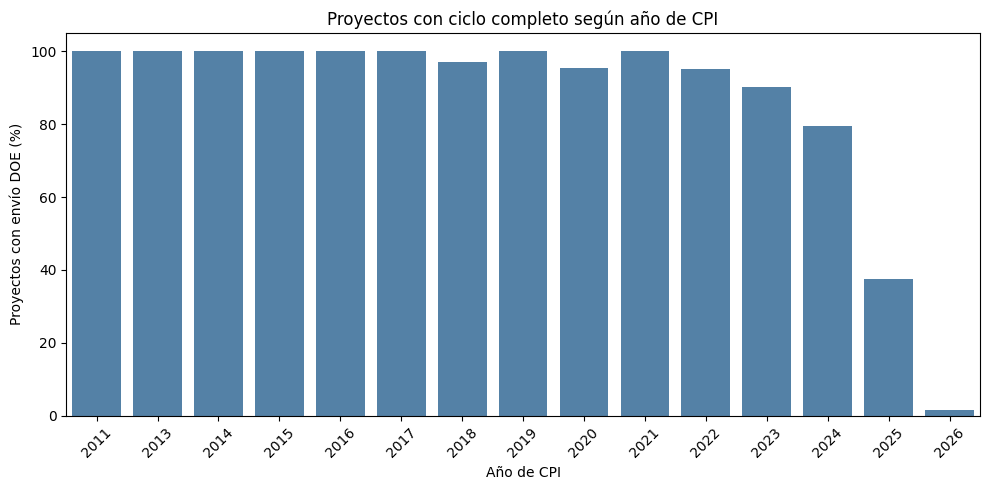

In [8]:
# 4.3. Duración por año de CPI

import matplotlib.pyplot as plt
import seaborn as sns

# Total de proyectos con CPI válido en cada año
base_cohortes = df_limpio[
    df_limpio["Fecha_CPI"].notna()
].copy()

base_cohortes["Anio_CPI"] = (
    base_cohortes["Fecha_CPI"].dt.year.astype(int)
)

total_por_anio = (
    base_cohortes.groupby("Anio_CPI")
    .size()
    .rename("Total_con_CPI")
)

# Duración de los proyectos con ciclo completo
duracion_anual = (
    df_analisis.groupby("Anio_CPI")["Duracion_CPI_DOE"]
    .agg(
        Proyectos_completos="count",
        Mediana_dias="median",
        Promedio_dias="mean"
    )
)

# Combinar resultados
tabla_anual = (
    total_por_anio.to_frame()
    .join(duracion_anual)
    .sort_index()
)

tabla_anual["Porcentaje_completos"] = (
    tabla_anual["Proyectos_completos"]
    / tabla_anual["Total_con_CPI"] * 100
)

print("DURACIÓN Y COMPLETITUD POR AÑO DE CPI")
display(tabla_anual.round(1))


# Porcentaje de proyectos con ciclo CPI-DOE completo
# según año de obtención del CPI

plt.figure(figsize=(10, 5))

sns.barplot(
    x=tabla_anual.index.astype(str),
    y=tabla_anual["Porcentaje_completos"],
    color="steelblue"
)

plt.title("Proyectos con ciclo completo según año de CPI")
plt.xlabel("Año de CPI")
plt.ylabel("Proyectos con envío DOE (%)")
plt.ylim(0, 105)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Interpretación:** La proporción de proyectos con ciclo CPI–DOE completo disminuye notablemente para los años de CPI recientes: en 2025 es del 37,5% y en 2026 del 1,7%. Por lo tanto, las duraciones observadas en esos años representan solo a quienes ya terminaron su ciclo y no permiten afirmar que los tiempos generales hayan mejorado.


### 4.4. Visualizaciones exploratorias


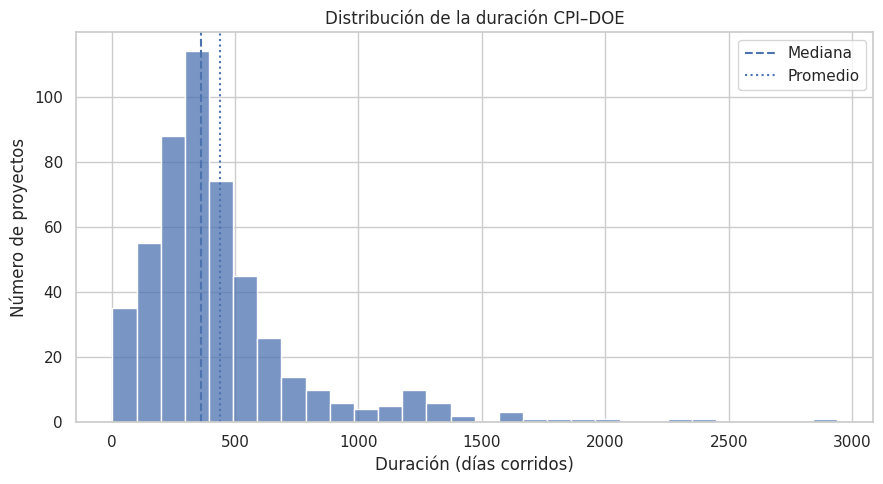

In [9]:
# 4.4. Visualizaciones exploratorias

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# GRÁFICO 1: Distribución de las duraciones
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df_analisis,
    x="Duracion_CPI_DOE",
    bins=30
)

plt.axvline(
    df_analisis["Duracion_CPI_DOE"].median(),
    linestyle="--",
    label="Mediana"
)

plt.axvline(
    df_analisis["Duracion_CPI_DOE"].mean(),
    linestyle=":",
    label="Promedio"
)

plt.title("Distribución de la duración CPI–DOE")
plt.xlabel("Duración (días corridos)")
plt.ylabel("Número de proyectos")
plt.legend()
plt.tight_layout()
plt.show()


**Interpretación:** La mayor parte de los proyectos se concentra en duraciones próximas a la mediana de 360,5 días, pero existen casos con tiempos mucho más altos. Esto genera una distribución asimétrica y eleva el promedio a 440,9 días.


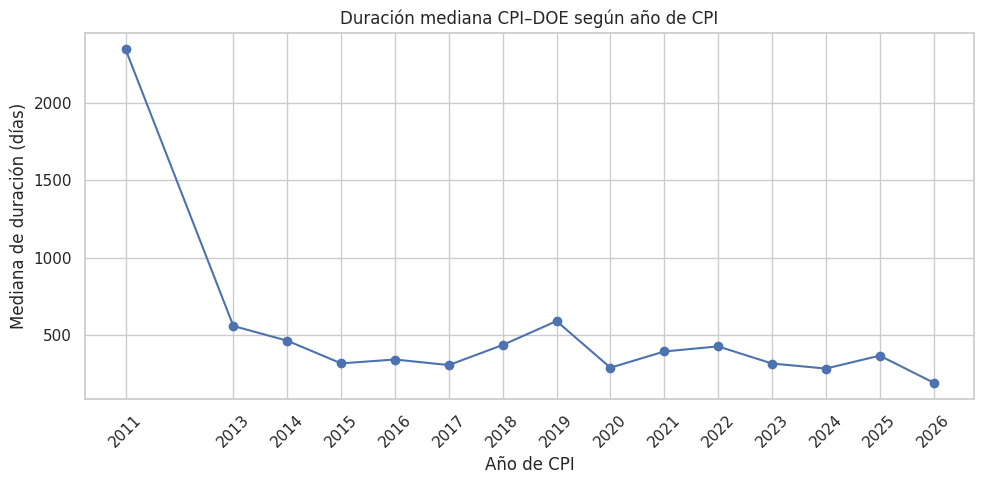

In [10]:
# 4.4. GRÁFICO 2: Mediana de duración por año de CPI
datos_anuales = tabla_anual.dropna(
    subset=["Mediana_dias"]
)

plt.figure(figsize=(10, 5))

plt.plot(
    datos_anuales.index,
    datos_anuales["Mediana_dias"],
    marker="o"
)

plt.title("Duración mediana CPI–DOE según año de CPI")
plt.xlabel("Año de CPI")
plt.ylabel("Mediana de duración (días)")
plt.xticks(datos_anuales.index, rotation=45)
plt.tight_layout()
plt.show()


**Interpretación:** La mediana de duración varía considerablemente entre años de CPI y no sigue una tendencia uniforme. Además, algunos períodos contienen pocos proyectos completos y, en los años recientes, muchos siguen sin registrar envío al DOE. Por eso, no se puede interpretar una mediana menor como una mejora general del proceso.


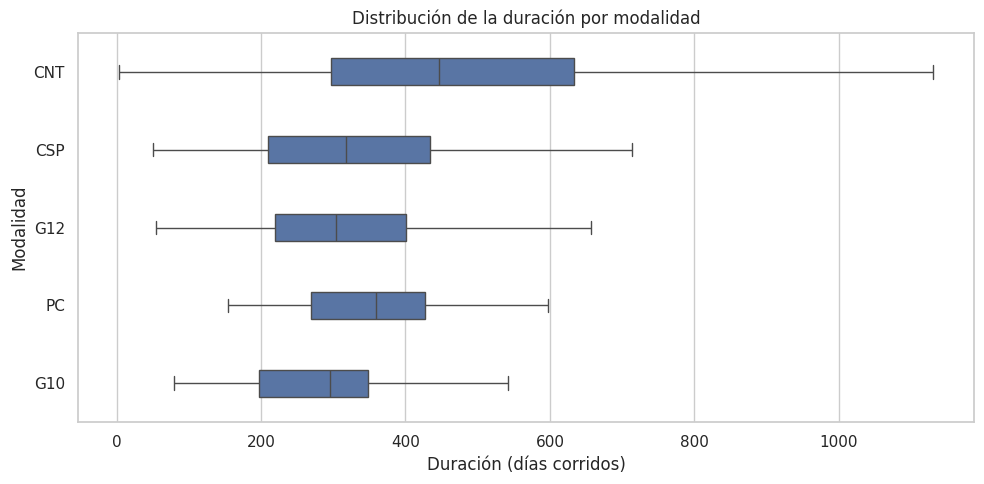

In [11]:
# 4.4. GRÁFICO 3: Duración según modalidad
orden = ["CNT", "CSP", "G12", "PC", "G10"]

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df_analisis,
    y="Modalidad",                 # Modalidades en eje vertical
    x="Duracion_CPI_DOE",         # Duración en eje horizontal
    order=orden,
    width=0.35,                   # Cajas más delgadas
    showfliers=False
)

plt.title("Distribución de la duración por modalidad")
plt.xlabel("Duración (días corridos)")
plt.ylabel("Modalidad")
plt.tight_layout()
plt.show()


**Interpretación:** La modalidad CNT registra una mediana superior a la de las otras modalidades principales (447 días), además de una mayor dispersión. Esto sugiere una posible relación entre modalidad y duración, que se examinará más adelante con la regresión.


### Principales resultados del análisis descriptivo

- **Variables para el análisis:** Se examinó la duración CPI–DOE como variable dependiente (Y), junto con el número de viviendas, modalidad, tipología, Entidad Patrocinante y año de CPI como posibles variables explicativas (X).

- **Proyectos analizados:** La muestra está compuesta por 504 proyectos de 93 Entidades Patrocinantes distintas. La mediana es de 52 viviendas por proyecto.

- **Selección de variables:** La tabla cruzada muestra una estrecha relación entre modalidad y tipología, aspecto que se considerará al construir el modelo para evitar incorporar información redundante.

**Conclusión preliminar:** Las duraciones presentan diferencias importantes entre proyectos y grupos. En la siguiente etapa se evaluará qué características ayudan a explicar esas variaciones y hasta qué punto permiten predecir los días del ciclo CPI–DOE.



## Etapa 5. Modelo analítico aplicado

Se utilizará una **regresión lineal múltiple** para estimar los días de tramitación entre el CPI y el envío al DOE, a partir de las características de los proyectos.

Se compararán dos modelos: uno que considera número de viviendas, modalidad y año de CPI, y otro que incorpora además la Entidad Patrocinante. Esto, pues la unidad técnica ha señalado que estiman que uno de los principales factores que inciden sobre el plazo de elaboración de un proyecto es la capacidad técnica de la respectiva Entidad Patrocinante.

La identificación de la Entidad Patrocinante se utiliza como variable explicativa, pero no constituye una medición directa de su capacidad técnica.

Cabe señalar que, a partir de los resultados de la tabla cruzada entre modalidad y tipología, se observa que ambas variables están estrechamente relacionadas, ya que determinadas modalidades se concentran principalmente en ciertas tipologías de proyectos.

Por esta razón, se decidió excluir la variable Tipología del modelo de regresión, evitando incorporar información redundante y reduciendo el riesgo de multicolinealidad entre las variables explicativas. Se mantuvo la variable Modalidad, considerando que permite diferenciar los principales grupos de proyectos analizados.

Para evaluar su desempeño, los datos se dividirán en entrenamiento (80%) y prueba (20%), utilizando las métricas MAE, RMSE y R².

También se revisarán los coeficientes, la multicolinealidad y los residuos, con el propósito de evaluar los supuestos básicos y las limitaciones de la regresión.

In [12]:
# Etapa 5: Modelo Analítico Aplicado
# 5.1. Preparación y separación de datos

from sklearn.model_selection import train_test_split

# Crear una base específica para la regresión
df_regresion = df_analisis.copy()

# Centrar el año de CPI en 2020
# Facilita la interpretación de los coeficientes
df_regresion["Anio_CPI_c"] = (
    df_regresion["Anio_CPI"].astype(int) - 2020
)

# Variables explicativas
variables_X = [
    "Numero_Viviendas",
    "Modalidad",
    "Anio_CPI_c",
    "Entidad_Patrocinante"
]

X = df_regresion[variables_X].copy()

# Variable dependiente: duración en días
y = df_regresion["Duracion_CPI_DOE"].astype(float)

# Agrupar los años en períodos para equilibrar la muestra
periodos = pd.cut(
    df_regresion["Anio_CPI"].astype(int),
    bins=[2010, 2016, 2020, 2023, 2026],
    labels=["2011-2016", "2017-2020",
            "2021-2023", "2024-2026"]
)

# Separar entrenamiento (80%) y prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=periodos
)

print("DISTRIBUCIÓN DE LOS DATOS")
print("Proyectos totales:", len(X))
print("Entrenamiento:", len(X_train))
print("Prueba:", len(X_test))

print("\nVARIABLES EXPLICATIVAS")
display(X_train.head())

DISTRIBUCIÓN DE LOS DATOS
Proyectos totales: 504
Entrenamiento: 403
Prueba: 101

VARIABLES EXPLICATIVAS


,Numero_Viviendas,Modalidad,Anio_CPI_c,Entidad_Patrocinante
513,352.0,G10,5,Unión Spa
469,54.0,G12,4,Cumbres del Norte Ltda.
294,128.0,CNT,1,Inmobiliaria Concrecasa Dos Ltda.
299,134.0,G12,1,Oval Ingenieros Asociados Ltda.
25,104.0,CNT,-6,Inmobiliaria Concrecasa Dos Ltda.


**Interpretación:** Se reservaron 403 proyectos para entrenamiento y 101 para prueba. La separación permite evaluar el desempeño del modelo en observaciones que no utilizó para ajustar sus coeficientes.


In [13]:
# 5.2. Entrenamiento de modelos de regresión lineal múltiple

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Función para construir una regresión
def crear_modelo(incluir_ep=False):

    categoricas = ["Modalidad"]

    if incluir_ep:
        categoricas.append("Entidad_Patrocinante")

    preparacion = ColumnTransformer(
        transformers=[
            ("numericas", "passthrough",
             ["Numero_Viviendas", "Anio_CPI_c"]),

            ("categoricas",
             OneHotEncoder(
                 drop="first",
                 handle_unknown="infrequent_if_exist",
                 min_frequency=10,
                 sparse_output=False
             ),
             categoricas)
        ],
        verbose_feature_names_out=False
    )

    return Pipeline([
        ("preprocesar", preparacion),
        ("regresion", LinearRegression())
    ])


# Modelo A: características del proyecto
modelo_A = crear_modelo(incluir_ep=False)
modelo_A.fit(X_train, y_train)

# Modelo B: características del proyecto + EP
modelo_B = crear_modelo(incluir_ep=True)
modelo_B.fit(X_train, y_train)

# Modelo de referencia: mediana histórica
modelo_referencia = DummyRegressor(strategy="median")
modelo_referencia.fit(X_train, y_train)


# Función para evaluar desempeño
def evaluar_modelo(nombre, modelo, X_datos, y_real, conjunto):

    pred = modelo.predict(X_datos)

    return {
        "Modelo": nombre,
        "Conjunto": conjunto,
        "MAE": mean_absolute_error(y_real, pred),
        "RMSE": np.sqrt(mean_squared_error(y_real, pred)),
        "R2": r2_score(y_real, pred)
    }


# Comparar sobre entrenamiento y prueba
resultados = []

modelos = {
    "Referencia (mediana)": modelo_referencia,
    "Modelo A - Sin EP": modelo_A,
    "Modelo B - Con EP": modelo_B
}

for nombre, modelo in modelos.items():

    resultados.append(
        evaluar_modelo(
            nombre, modelo,
            X_train, y_train, "Entrenamiento"
        )
    )

    resultados.append(
        evaluar_modelo(
            nombre, modelo,
            X_test, y_test, "Prueba"
        )
    )

comparacion_modelos = pd.DataFrame(resultados)

print("COMPARACIÓN DE DESEMPEÑO")
display(
    comparacion_modelos.round({
        "MAE": 1,
        "RMSE": 1,
        "R2": 3
    })
)

COMPARACIÓN DE DESEMPEÑO


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


,Modelo,Conjunto,MAE,RMSE,R2
0,Referencia (mediana),Entrenamiento,200.4,324.0,-0.050
1,Referencia (mediana),Prueba,269.8,474.9,-0.070
2,Modelo A - Sin EP,Entrenamiento,203.1,303.0,0.082
3,Modelo A - Sin EP,Prueba,268.5,433.6,0.108
4,Modelo B - Con EP,Entrenamiento,191.7,281.6,0.207
5,Modelo B - Con EP,Prueba,249.5,405.0,0.222



### Resultados preliminares de los modelos

- **Comparación:** El Modelo B, que incorpora la Entidad Patrocinante, obtuvo mejores resultados que el Modelo A en los tres indicadores de evaluación.

- **Error predictivo:** El MAE disminuyó de 268,5 a 249,5 días al incorporar la EP, equivalente a una mejora del 7,1%.

- **Capacidad explicativa:** El Modelo B obtuvo un R² de 0,222 en los datos de prueba, por lo que gran parte de la variabilidad en los tiempos de tramitación todavía no es explicada por las variables seleccionadas.

- **Posible sobreajuste:** El Modelo B presenta un MAE de 191,7 días en entrenamiento y de 249,5 días en prueba. Esta diferencia de 57,8 días podría indicar cierto grado de sobreajuste. Será necesario evaluar este comportamiento con mayor profundidad.

- **Otras limitaciones:** Aunque incorporar la EP mejora las predicciones, el margen de error sigue siendo considerable. Además, algunas categorías no estuvieron presentes durante el entrenamiento.

**Conclusión preliminar:** La Entidad Patrocinante parece aportar información relevante para predecir la duración del ciclo CPI-DOE, aunque el desempeño obtenido todavía es limitado para realizar estimaciones individuales precisas.

In [14]:
# 5.3. Coeficientes y diagnóstico del Modelo B

import statsmodels.api as sm
from scipy.stats import jarque_bera
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import (
    variance_inflation_factor
)

# Recuperar las variables transformadas del Modelo B
preprocesador_B = modelo_B.named_steps["preprocesar"]

X_codificado = pd.DataFrame(
    preprocesador_B.transform(X_train),
    columns=preprocesador_B.get_feature_names_out(),
    index=X_train.index
).astype(float)

# Incorporar intercepto
X_ols = sm.add_constant(
    X_codificado,
    has_constant="add"
)

# Regresión con errores estándar robustos
regresion_ols = sm.OLS(
    y_train, X_ols
).fit(cov_type="HC3")

print("RESUMEN DE REGRESIÓN LINEAL MÚLTIPLE")
print(regresion_ols.summary())

# Multicolinealidad mediante VIF
vif = pd.DataFrame({
    "Variable": X_codificado.columns,
    "VIF": [
        variance_inflation_factor(X_ols.values, i)
        for i in range(1, X_ols.shape[1])
    ]
})

print("\nMULTICOLINEALIDAD (VIF)")
display(vif.sort_values("VIF", ascending=False).round(2))

# Diagnóstico de residuos
residuos = regresion_ols.resid

jb = jarque_bera(residuos)
bp = het_breuschpagan(residuos, X_ols)

print("\nDIAGNÓSTICO DE SUPUESTOS")
print(f"Normalidad (Jarque-Bera), p: {jb.pvalue:.4f}")
print(f"Homocedasticidad (Breusch-Pagan), p: {bp[1]:.4f}")

RESUMEN DE REGRESIÓN LINEAL MÚLTIPLE
                            OLS Regression Results                            
Dep. Variable:       Duracion_CPI_DOE   R-squared:                       0.207
Model:                            OLS   Adj. R-squared:                  0.169
Method:                 Least Squares   F-statistic:                     5.147
Date:                Wed, 25 Nov 2026   Prob (F-statistic):           1.28e-10
Time:                        18:08:47   Log-Likelihood:                -2845.0
No. Observations:                 403   AIC:                             5728.
Df Residuals:                     384   BIC:                             5804.
Df Model:                          18                                         
Covariance Type:                  HC3                                         
                                                               coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------

,Variable,VIF
17,Entidad_Patrocinante_infrequent_sklearn,7.57
13,Entidad_Patrocinante_Serey y Otros Asociados S.A.,4.10
11,Entidad_Patrocinante_Inmobiliaria Concrecasa D...,3.98
12,Entidad_Patrocinante_Oval Ingenieros Asociados...,2.86
7,Entidad_Patrocinante_Consolida SPA,2.74
2,Modalidad_CSP,2.73
15,Entidad_Patrocinante_Sociedad Tecnoingeniería ...,2.29
5,Modalidad_PC,2.26
16,Entidad_Patrocinante_Veyese Consultores Ltda.,2.19
14,Entidad_Patrocinante_Serviu Metropolitano,1.90



DIAGNÓSTICO DE SUPUESTOS
Normalidad (Jarque-Bera), p: 0.0000
Homocedasticidad (Breusch-Pagan), p: 0.0000


### Resultados preliminares del modelo y análisis de sus limitaciones

A partir de la construcción y evaluación de los modelos de regresión lineal múltiple, se obtuvieron los siguientes resultados:

- **Desempeño predictivo:** El Modelo B, que incorpora la Entidad Patrocinante, presentó los mejores resultados en el conjunto de prueba, con un MAE de 249,5 días, un RMSE de 405 días y un R² de 0,222. Aunque mejora respecto del modelo sin EP, su capacidad predictiva sigue siendo limitada.

- **Diferencia entre entrenamiento y prueba:** El MAE del Modelo B aumenta de 191,7 días en entrenamiento a 249,5 días en prueba. Aunque esta diferencia podría relacionarse con sobreajuste, también puede reflejar diferencias entre los proyectos de ambos conjuntos. Se realizará una validación cruzada K-Fold para evaluar la estabilidad del desempeño.

- **Variables explicativas:** La modalidad y algunas Entidades Patrocinantes presentan asociaciones estadísticamente significativas con los tiempos de tramitación. En cambio, el número de viviendas y el año de CPI no resultaron significativos al nivel del 5%.

- **Multicolinealidad:** Los valores VIF no evidenciaron problemas severos de manera general, aunque algunas categorías presentan valores más elevados.

- **Supuestos de la regresión:** Las pruebas de Jarque-Bera y Breusch-Pagan entregaron valores p inferiores a 0,001, indicando que los residuos no siguen una distribución normal y que existe evidencia de heterocedasticidad. Para considerar esta última condición en la inferencia estadística, se utilizaron errores estándar robustos HC3.

**Análisis complementario de residuos**

Considerando que en el análisis exploratorio se identificaron proyectos con duraciones extraordinariamente largas, surge la hipótesis de que el modelo podría presentar mayores errores al predecir estos casos.

Para investigarlo, se analizará la distribución de los residuos y su relación con las duraciones reales de los proyectos del conjunto de prueba. Esto permitirá identificar posibles patrones de subestimación o sobreestimación y comprobar si los errores de mayor magnitud se concentran en los proyectos de tramitación más prolongada.

Este análisis busca comprender las limitaciones predictivas del modelo antes de evaluar posibles mejoras.

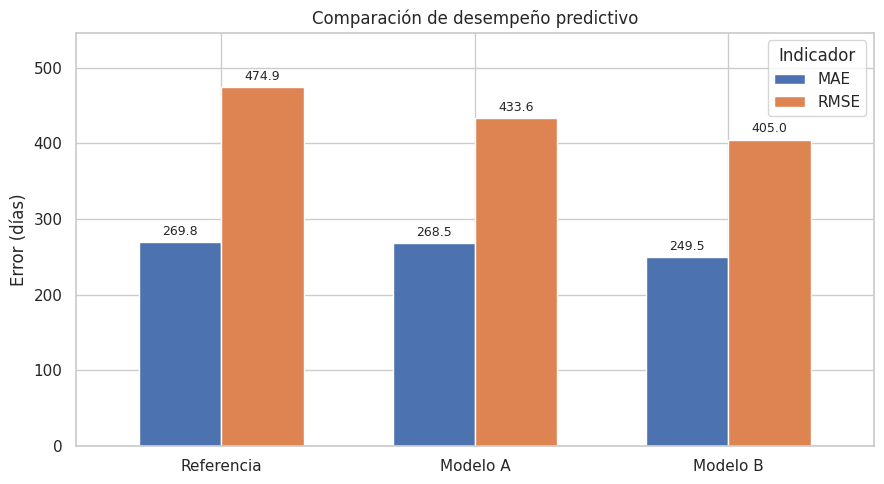

In [15]:
# 5.4. Comparación gráfica del desempeño predictivo

import matplotlib.pyplot as plt

datos_prueba = comparacion_modelos[
    comparacion_modelos["Conjunto"] == "Prueba"
].copy()

datos_prueba["Modelo"] = [
    "Referencia",
    "Modelo A",
    "Modelo B"
]

ax = (
    datos_prueba
    .set_index("Modelo")[["MAE", "RMSE"]]
    .plot.bar(figsize=(9, 5), rot=0, width=0.65)
)

ax.set_title("Comparación de desempeño predictivo")
ax.set_xlabel("")
ax.set_ylabel("Error (días)")
ax.legend(title="Indicador")

for barras in ax.containers:
    ax.bar_label(
        barras,
        fmt="%.1f",
        padding=3,
        fontsize=9
    )

ax.set_ylim(
    0,
    datos_prueba[["MAE", "RMSE"]].max().max() * 1.15
)

plt.tight_layout()
plt.show()

**Interpretación:** En la división inicial de entrenamiento y prueba, el Modelo B (con Entidad Patrocinante) obtuvo errores menores que el Modelo A y la referencia. Sin embargo, el MAE y el RMSE continúan siendo altos para estimar la duración de proyectos individuales.


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


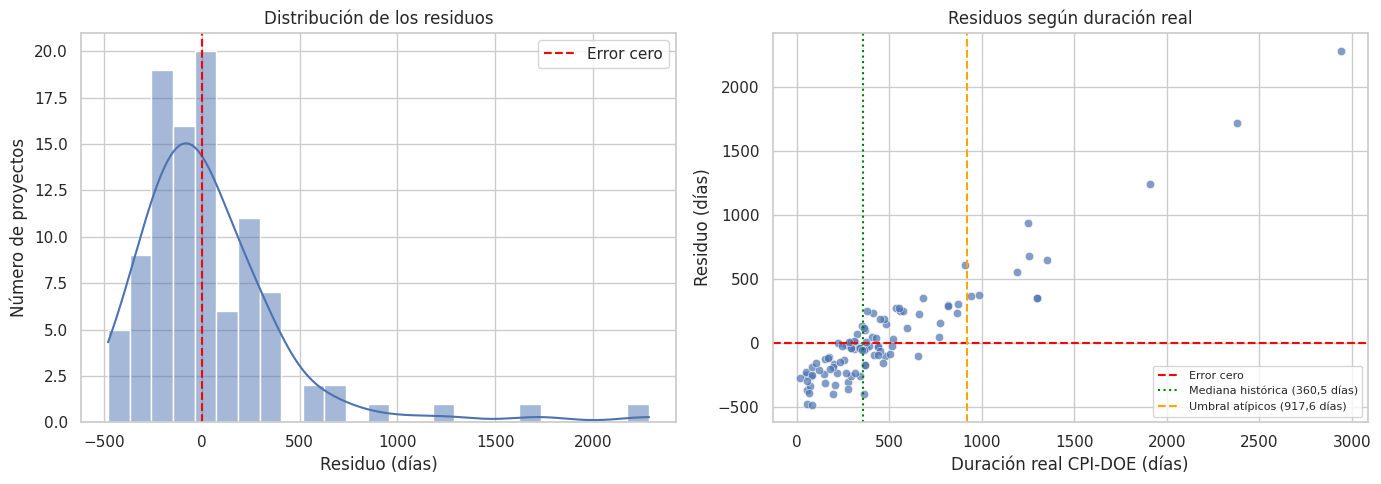

In [16]:
# 5.5. Distribución y análisis de residuos - Modelo B

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Predicciones sobre los 101 proyectos de prueba
y_pred = modelo_B.predict(X_test)

# Construir base de análisis
df_residuos = pd.DataFrame({
    "Duracion_Real": y_test.to_numpy(),
    "Duracion_Predicha": y_pred
})

# Residuo positivo = el modelo subestimó
# Residuo negativo = el modelo sobreestimó
df_residuos["Residuo"] = (
    df_residuos["Duracion_Real"] -
    df_residuos["Duracion_Predicha"]
)

# Crear ambos gráficos
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# GRÁFICO 1: Distribución de los residuos
sns.histplot(
    df_residuos["Residuo"],
    bins=25,
    kde=True,
    ax=ax[0]
)

ax[0].axvline(0, color="red", linestyle="--",
              label="Error cero")

ax[0].set_title("Distribución de los residuos")
ax[0].set_xlabel("Residuo (días)")
ax[0].set_ylabel("Número de proyectos")
ax[0].legend()

# GRÁFICO 2: Duración real versus residuo
sns.scatterplot(
    data=df_residuos,
    x="Duracion_Real",
    y="Residuo",
    alpha=0.7,
    ax=ax[1]
)

ax[1].axhline(0, color="red", linestyle="--",
              label="Error cero")

ax[1].axvline(
    360.5, color="green", linestyle=":",
    label="Mediana histórica (360,5 días)"
)

ax[1].axvline(
    917.6, color="orange", linestyle="--",
    label="Umbral atípicos (917,6 días)"
)

ax[1].set_title("Residuos según duración real")
ax[1].set_xlabel("Duración real CPI-DOE (días)")
ax[1].set_ylabel("Residuo (días)")
ax[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

### Resultados del análisis complementario de residuos

- **Distribución de los residuos:** Las pruebas estadísticas realizadas sobre el conjunto de entrenamiento evidenciaron falta de normalidad y heterocedasticidad.

- **Comportamiento de las predicciones:** En los gráficos del conjunto de prueba se observa que los proyectos con duraciones extraordinariamente largas presentan residuos positivos de gran magnitud. Esto indica que el Modelo B tiende a subestimar estos casos.

- **Implicancias:** Los errores extremos podrían estar contribuyendo al RMSE elevado. Si bien se utilizaron errores estándar robustos HC3 para la inferencia estadística, esto no modifica la precisión de las predicciones.

**Conclusión:** El modelo muestra dificultades para estimar las duraciones extraordinariamente largas, por lo que es necesario evaluar la estabilidad de su desempeño antes de considerar posibles mejoras.

### 5.6. Validación cruzada K-Fold

Para evaluar la estabilidad de los modelos y profundizar en la posible existencia de sobreajuste, se realizará una validación cruzada K-Fold con cinco particiones.

El procedimiento utilizará los 403 proyectos del conjunto de entrenamiento. En cada iteración, aproximadamente el 80% de estos proyectos se utilizará para entrenar y el 20% restante para validar, rotando los conjuntos hasta completar cinco evaluaciones.

Se compararán los indicadores MAE, RMSE y R² de ambos modelos, además de las diferencias entre los errores de entrenamiento y validación.

Esto permitirá determinar si la mejora observada al incorporar la Entidad Patrocinante se mantiene en distintas particiones de los datos.

In [17]:
# 5.6. Validación cruzada K-Fold

from sklearn.model_selection import KFold, cross_validate

# Definir las cinco particiones
kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Indicadores de evaluación
metricas = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "r2": "r2"
}

# Modelos que se compararán
modelos_cv = {
    "Referencia": modelo_referencia,
    "Modelo A - Sin EP": modelo_A,
    "Modelo B - Con EP": modelo_B
}

resultados_cv = []

for nombre, modelo in modelos_cv.items():

    evaluacion = cross_validate(
        modelo,
        X_train,
        y_train,
        cv=kfold,
        scoring=metricas,
        return_train_score=True
    )

    for i in range(5):
        resultados_cv.append({
            "Modelo": nombre,
            "Fold": i + 1,
            "MAE_Entrenamiento":
                -evaluacion["train_mae"][i],
            "MAE_Validacion":
                -evaluacion["test_mae"][i],
            "RMSE_Validacion":
                -evaluacion["test_rmse"][i],
            "R2_Validacion":
                evaluacion["test_r2"][i]
        })

df_kfold = pd.DataFrame(resultados_cv)

print("RESULTADOS POR PARTICIÓN")
display(df_kfold.round(2))

# Resumen de las cinco evaluaciones
resumen_kfold = df_kfold.groupby("Modelo").agg(
    MAE_Entrenamiento=("MAE_Entrenamiento", "mean"),
    MAE_Validacion=("MAE_Validacion", "mean"),
    Desviacion_MAE=("MAE_Validacion", "std"),
    RMSE_Validacion=("RMSE_Validacion", "mean"),
    R2_Validacion=("R2_Validacion", "mean")
)

resumen_kfold["Brecha_MAE"] = (
    resumen_kfold["MAE_Validacion"] -
    resumen_kfold["MAE_Entrenamiento"]
)

print("\nRESUMEN DE VALIDACIÓN CRUZADA")
display(resumen_kfold.round(2))

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


RESULTADOS POR PARTICIÓN


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


,Modelo,Fold,MAE_Entrenamiento,MAE_Validacion,RMSE_Validacion,R2_Validacion
0,Referencia,1,211.02,158.20,247.94,-0.02
1,Referencia,2,192.55,231.62,381.08,-0.06
2,Referencia,3,195.79,218.88,324.55,-0.12
3,Referencia,4,192.34,232.94,398.23,-0.06
4,Referencia,5,210.25,160.99,233.57,-0.01
5,Modelo A - Sin EP,1,214.75,179.80,249.22,-0.03
6,Modelo A - Sin EP,2,193.16,230.30,360.04,0.05
7,Modelo A - Sin EP,3,198.91,202.91,291.49,0.10
8,Modelo A - Sin EP,4,192.31,238.67,369.67,0.08
9,Modelo A - Sin EP,5,214.72,181.67,243.39,-0.10



RESUMEN DE VALIDACIÓN CRUZADA


,MAE_Entrenamiento,MAE_Validacion,Desviacion_MAE,RMSE_Validacion,R2_Validacion,Brecha_MAE
Modelo,,,,,,
Modelo A - Sin EP,202.77,206.67,27.13,302.76,0.02,3.90
Modelo B - Con EP,192.50,205.90,33.54,293.94,0.08,13.40
Referencia,200.39,200.53,37.78,317.07,-0.05,0.14


### Resultados de la validación cruzada K-Fold

- **Desempeño del Modelo B:** El modelo que incorpora la Entidad Patrocinante obtuvo el mejor RMSE (293,94 días) y R² (0,08). Sin embargo, estos resultados muestran que todavía tiene una capacidad limitada para predecir los tiempos de tramitación.

- **Comparación de modelos:** El Modelo B presentó un MAE muy similar al Modelo A (205,90 y 206,67 días, respectivamente). Incluso el modelo de referencia obtuvo un MAE menor (200,53 días). Por lo tanto, incorporar la EP no mejora todos los indicadores.

- **Posible sobreajuste:** La diferencia entre el error de entrenamiento y validación del Modelo B fue de 13,40 días en promedio, bastante menor que la observada inicialmente. Esto sugiere que el sobreajuste no sería un problema tan importante como se sospechó inicialmente, aunque no se puede descartar por completo.

- **Variación de los resultados:** El MAE del Modelo B cambió entre 167,35 y 256,14 días según los proyectos utilizados para validarlo. Esto demuestra que los resultados dependen en parte de cómo se divide la muestra.

**Conclusión:** La validación cruzada muestra que incorporar la Entidad Patrocinante puede ayudar a mejorar algunas predicciones, especialmente al reducir los errores más grandes. Sin embargo, la mejora es pequeña y el modelo todavía presenta dificultades para estimar con precisión los tiempos de tramitación.

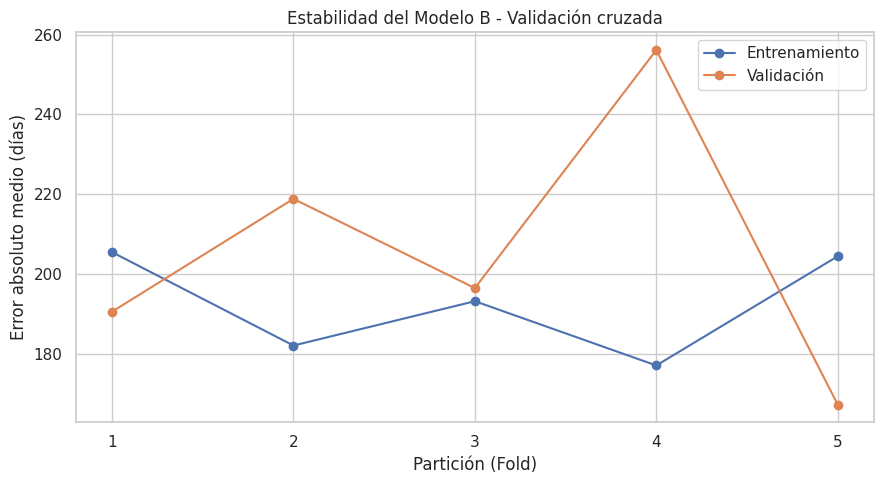

In [18]:
# 5.7. Estabilidad del Modelo B en validación cruzada

datos_B = df_kfold[
    df_kfold["Modelo"] == "Modelo B - Con EP"
].copy()

plt.figure(figsize=(9, 5))

plt.plot(
    datos_B["Fold"],
    datos_B["MAE_Entrenamiento"],
    marker="o",
    label="Entrenamiento"
)

plt.plot(
    datos_B["Fold"],
    datos_B["MAE_Validacion"],
    marker="o",
    label="Validación"
)

plt.title("Estabilidad del Modelo B - Validación cruzada")
plt.xlabel("Partición (Fold)")
plt.ylabel("Error absoluto medio (días)")
plt.xticks([1, 2, 3, 4, 5])
plt.legend()
plt.tight_layout()
plt.show()

**Interpretación:** El MAE de entrenamiento y validación cambia entre las cinco particiones del Modelo B, y el error de validación no es siempre mayor. La diferencia no se repite de manera uniforme, por lo que los resultados no muestran evidencia consistente de sobreajuste severo, aunque sí sensibilidad a la composición de cada grupo.


### 5.8. Comparación con una regresión logarítmica

Considerando que los tiempos de tramitación presentan una distribución asimétrica y que el modelo tiene dificultades para predecir las duraciones más largas, se evaluará una regresión que utilice el logaritmo natural de la duración CPI-DOE.

El objetivo es comprobar si esta transformación permite mejorar el desempeño predictivo y reducir la influencia de los valores extremos, sin eliminar proyectos de la muestra.

Para comparar ambos modelos se utilizarán las mismas cinco particiones del K-Fold. Las predicciones del modelo logarítmico se convertirán nuevamente a días, de manera que los indicadores MAE, RMSE y R² sean comparables.

In [19]:
# 5.8. Comparación con regresión logarítmica

from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import cross_validate

# Modelo B con transformación logarítmica de Y
modelo_B_log = TransformedTargetRegressor(
    regressor=crear_modelo(incluir_ep=True),
    func=np.log,
    inverse_func=np.exp
)

# Validación cruzada con las mismas 5 particiones
resultado_log = cross_validate(
    modelo_B_log,
    X_train,
    y_train,
    cv=kfold,
    scoring=metricas
)

# Comparar con el Modelo B original
comparacion_log = pd.DataFrame({
    "Modelo": [
        "Modelo B original",
        "Modelo B logarítmico"
    ],
    "MAE": [
        resumen_kfold.loc[
            "Modelo B - Con EP", "MAE_Validacion"
        ],
        -resultado_log["test_mae"].mean()
    ],
    "RMSE": [
        resumen_kfold.loc[
            "Modelo B - Con EP", "RMSE_Validacion"
        ],
        -resultado_log["test_rmse"].mean()
    ],
    "R2": [
        resumen_kfold.loc[
            "Modelo B - Con EP", "R2_Validacion"
        ],
        resultado_log["test_r2"].mean()
    ]
})

print("COMPARACIÓN DE MODELOS")
display(comparacion_log.round(2))

COMPARACIÓN DE MODELOS


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown ca

,Modelo,MAE,RMSE,R2
0,Modelo B original,205.90,293.94,0.08
1,Modelo B logarítmico,194.25,306.01,0.02


### Resultados de la comparación logarítmica

- **Error predictivo:** El modelo logarítmico redujo el MAE de 205,90 a 194,25 días. Sin embargo, el RMSE aumentó de 293,94 a 306,01 días y el R² disminuyó de 0,08 a 0,02. Por lo tanto, mejoró el error promedio, pero no los demás indicadores.

- **Supuestos del modelo:** La transformación logarítmica se evaluó como una alternativa para reducir la influencia de las duraciones extremas. Sin embargo, no se realizaron nuevas pruebas de los supuestos sobre los residuos transformados, por lo que no es posible concluir si estos mejoraron.

- **Comparación:** Aunque el modelo logarítmico presenta un menor error absoluto promedio, sigue teniendo dificultades con los errores de mayor magnitud.

**Conclusión:** La transformación logarítmica permitió mejorar algunos resultados, pero no representó una mejora general del modelo. Por esta razón, se mantendrá el Modelo B original como principal y la versión logarítmica como una comparación complementaria.

### Conclusión general de la Etapa 5

En relación con el **objetivo general**, se logró desarrollar y evaluar un modelo de regresión lineal múltiple para estimar los tiempos de tramitación de proyectos DS49 entre la obtención del CPI y su envío al DOE. Sin embargo, los resultados muestran que las características disponibles permiten explicar solo una parte de las diferencias en las duraciones, por lo que su utilidad para realizar predicciones individuales todavía es limitada.

Respecto de los **objetivos específicos**, se concluye lo siguiente:

1. **Caracterización de los tiempos de tramitación:** Se identificó una importante variabilidad entre los 504 proyectos analizados, incluyendo casos con duraciones extraordinariamente largas. Esto demuestra que los tiempos de tramitación no presentan un comportamiento uniforme.

2. **Relación con las características de los proyectos:** La modalidad y algunas Entidades Patrocinantes presentan asociaciones significativas con la duración. En cambio, el número de viviendas y el año de CPI no mostraron relaciones estadísticamente significativas en el modelo. La tipología se excluyó por su estrecha relación con la modalidad.

3. **Construcción y evaluación del modelo:** Incorporar la Entidad Patrocinante mejoró algunos indicadores predictivos, aunque la validación cruzada mostró que esta mejora no es consistente en todos ellos. La transformación logarítmica tampoco logró una mejora general, por lo que se mantuvo el modelo original como principal.

4. **Identificación de patrones y recomendaciones:** Se observó que el modelo tiende a subestimar las duraciones extraordinariamente largas. Esto sugiere que las características generales de los proyectos no son suficientes para representar todas las situaciones que pueden prolongar su tramitación. Por ello, sería recomendable incorporar en futuros análisis información sobre observaciones, subsanaciones, tiempos de respuesta y otras actividades desarrolladas durante el proceso.

**Balance de la etapa:** Se logró desarrollar, comparar y diagnosticar un modelo predictivo, identificando tanto las asociaciones que captura como sus limitaciones. Las implicancias y propuestas para la gestión se presentan en la Etapa 7.

## Etapa 6. Gráficas y visualizaciones

Las visualizaciones se incorporaron en las etapas 4 y 5, junto a los análisis correspondientes, para facilitar su interpretación.

Los gráficos descriptivos permitieron observar la distribución de los tiempos de tramitación, las diferencias entre modalidades y años de CPI, y la proporción de proyectos con ciclo completo.

Por su parte, los gráficos del modelo permitieron comparar su desempeño predictivo, identificar errores de mayor magnitud y analizar la estabilidad de los resultados mediante K-Fold.

En conjunto, estas visualizaciones ayudaron a identificar patrones relevantes para comprender el comportamiento de los proyectos y las limitaciones del modelo.

## Etapa 7. Conclusiones y propuestas de mejora

### Respuesta a la pregunta de investigación

Las características de los proyectos DS49 permiten explicar parcialmente sus tiempos de tramitación entre el CPI y el envío al DOE.

La modalidad y algunas Entidades Patrocinantes presentan asociaciones relevantes con la duración. Sin embargo, los resultados muestran que estas variables no son suficientes para generar predicciones individuales con un nivel de precisión adecuado para la planificación institucional.

### Propuestas de mejora

**1. Mejorar el registro de los tiempos de revisión y subsanación.**

Se recomienda fortalecer la trazabilidad del proceso, registrando las fechas de observaciones, respuestas de las Entidades Patrocinantes y nuevas revisiones. Esto permitiría distinguir los tiempos atribuibles a cada etapa e incorporar variables más directamente relacionadas con la duración de los proyectos en futuros modelos.

**2. Fortalecer el seguimiento de proyectos con tramitaciones prolongadas.**

Se propone incorporar indicadores que permitan identificar proyectos que superen los tiempos históricos habituales según su modalidad y estado de avance. Esto facilitaría priorizar revisiones de cartera, detectar situaciones que requieren seguimiento y apoyar la coordinación de los equipos.

### Consideraciones finales

Los resultados constituyen un primer acercamiento al uso de herramientas predictivas para el seguimiento de proyectos habitacionales. Aunque el modelo presenta limitaciones, permitió identificar factores asociados a la duración y necesidades de información que podrían contribuir a mejorar la gestión del proceso.

Las predicciones no deben utilizarse como plazos comprometidos, sino como antecedentes exploratorios para orientar futuras mejoras.
